# Bitcoin: SVR and a voting ensemble (Filip)

**Task (same as the rest of the project).** From the last 7 days of hourly data (168 hours), predict for each of the next 24 hours how much the price grows or shrinks compared with the hour before: `Close[h] / Close[h-1] − 1`, in %.

**What this notebook adds.** The team has already tried Ridge, Lasso, kNN, Random Forest, Gradient Boosting, MLP (Alberto) and RNN/LSTM (Adrián). Two course topics were still missing:

1. **Support Vector Regression (SVR)**, linear and with an RBF kernel.
2. **A voting ensemble**: the average of SVR, Ridge, Random Forest and Gradient Boosting.

To keep the results directly comparable with `bitcoin-models-new-data.ipynb`, this notebook reuses **exactly** the same features, training period, walk-forward cross-validation and metrics.

## 1. Shared setup from Alberto's notebook

Data, the 42 features, the training period, the walk-forward folds, the metrics and the helpers `cv_tune`, `best_params` and `final_report` come from `bitcoin-models-new-data.ipynb` through `shared_cells.py`, so nothing is copied. Main metric: **MAE skill** = `1 − MAE_model / MAE_zero` (0 = as good as predicting no change).

In [1]:
from shared_cells import run_shared_cells

run_shared_cells(globals())

from sklearn.svm import SVR, LinearSVR

42 features | train 9950 windows (2017-01-01 -> 2023-10-24) | test 25815 windows (2023-10-25 -> 2026-10-05) | 4 CV folds


## 2. Baselines

- **Zero**: predict "no change" (ratio 1.0) for every hour. For a random walk this is the best possible forecast, so every model is measured against it.
- **Mean per hour**: the average training return of each of the 24 hours (≈ "always slightly up").

In [2]:
final_report("Baseline: zero", pred=np.zeros_like(Yte))
final_report("Baseline: mean per hour", pred=np.tile(Ytr.mean(0), (len(Yte), 1)));

Baseline: zero                     MAE=0.3251  skill=+0.0000  R2oos=+0.0000  IC=+nan  HourDir=0.493  DayDir=0.466 (p=0.99)  DayBalAcc=0.500
Baseline: mean per hour            MAE=0.3252  skill=-0.0004  R2oos=-0.0003  IC=+0.000  HourDir=0.504  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


## 3. Support Vector Regression (SVR)

SVR fits a function and **ignores every error smaller than ε** (the "ε-tube"). Only points outside the tube (the support vectors) shape the model. For a target that is mostly noise this is an attractive property: small random hourly moves are simply not learned.

| Hyperparameter | Effect |
|---|---|
| `epsilon` | Width of the tube, in % (the target unit). Larger → more of the noise is ignored. The average hourly move is ≈ 0.3–0.4 %. |
| `C` | How much errors outside the tube are penalised. **Small C = strong regularisation** (flatter function, closer to a constant). |
| `gamma` (RBF only) | How local the RBF kernel is. Large → very wiggly function, risk of overfitting. |

SVR predicts a single number, so it is wrapped in `MultiOutputRegressor`: **one SVR per predicted hour** (24 models). SVM is distance-based, so the features are standardized first.

### 3.1 Linear SVR

Fast (a linear model like Ridge, but with the ε-insensitive loss instead of squared error).

,C,epsilon,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.0000,0.1,0.0009,0.0001,0.0001,0.4351,0.0141,0.4925,0.3
1,0.0000,0.0,0.0009,0.0001,0.0001,0.4351,0.0138,0.4952,0.3
2,0.0000,0.3,0.0007,0.0001,0.0001,0.4351,0.0135,0.4849,0.3
3,0.0001,0.0,0.0045,-0.0004,0.0011,0.4352,0.0187,0.5006,0.3
4,0.0001,0.1,0.0043,-0.0004,0.0014,0.4353,0.0189,0.4972,0.3
5,0.0001,0.3,0.0036,-0.0006,0.0011,0.4353,0.0171,0.4864,0.3
6,0.0010,0.1,0.0084,-0.0054,0.0062,0.4374,0.0230,0.5075,0.5
7,0.0010,0.0,0.0090,-0.0056,0.0061,0.4374,0.0213,0.5075,0.4
8,0.0010,0.3,0.0070,-0.0066,0.0056,0.4379,0.0209,0.5019,0.4
9,0.0100,0.1,0.0094,-0.0107,0.0129,0.4396,0.0220,0.5084,1.3


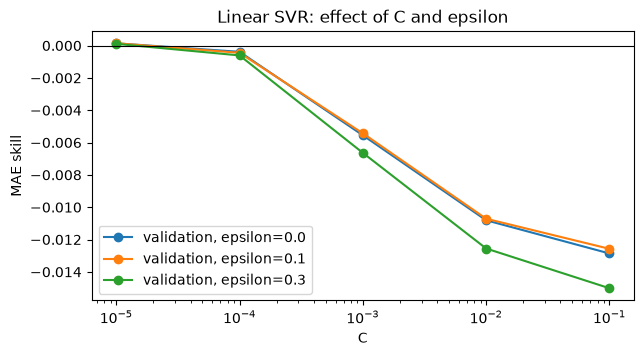

Linear SVR {'C': 1e-05, 'epsilon': 0.1} MAE=0.3251  skill=-0.0000  R2oos=-0.0000  IC=+0.003  HourDir=0.501  DayDir=0.484 (p=0.86)  DayBalAcc=0.480


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('multioutputregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](42,)","[ 0.02, 0. , 0.01,..., 0. ,-0. , 0. ]"


In [3]:
make_lsvr = lambda C, epsilon: make_pipeline(StandardScaler(), MultiOutputRegressor(
    LinearSVR(C=C, epsilon=epsilon, max_iter=10_000,
              dual="auto", random_state=RANDOM_STATE)))
lsvr_cv = cv_tune(make_lsvr, {"C": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1], "epsilon": [0.0, 0.1, 0.3]})

fig, ax = plt.subplots(figsize=(7, 3.5))
for eps, t in lsvr_cv.sort_values("C").groupby("epsilon"):
    ax.semilogx(t["C"], t["val_skill"], "o-", label=f"validation, epsilon={eps}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("C"); ax.set_ylabel("MAE skill"); ax.set_title("Linear SVR: effect of C and epsilon"); ax.legend()
plt.show()

p_lsvr = best_params(lsvr_cv, ["C", "epsilon"])
final_report(f"Linear SVR {p_lsvr}", make_lsvr(**p_lsvr))

### 3.2 SVR with an RBF kernel

The RBF kernel lets SVR learn non-linear patterns. Training cost grows roughly with the square of the number of samples, which is fine here (≈ 10,000 training windows), but 24 outputs × 4 folds × the grid means hundreds of fits. They run in parallel (`n_jobs=-1`), and the grid is kept small.

In [4]:
make_rbf = lambda C, epsilon, gamma: make_pipeline(StandardScaler(), MultiOutputRegressor(
    SVR(kernel="rbf", C=C, epsilon=epsilon, gamma=gamma, cache_size=1000), n_jobs=-1))
rbf_cv = cv_tune(make_rbf, {"C": [0.01, 0.1, 1.0], "epsilon": [0.1, 0.3], "gamma": ["scale", 0.003]})

p_rbf = best_params(rbf_cv, ["C", "epsilon", "gamma"])
final_report(f"RBF SVR {p_rbf}", make_rbf(**p_rbf))

,C,epsilon,gamma,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.01,0.1,0.003,0.0036,-0.0010,0.0024,0.4355,0.0172,0.5141,39.7
1,0.01,0.3,0.003,0.0030,-0.0014,0.0027,0.4357,0.0164,0.5156,27.4
2,0.01,0.1,scale,0.0091,-0.0014,0.0026,0.4357,0.0163,0.5128,41.0
3,0.01,0.3,scale,0.0071,-0.0017,0.0025,0.4358,0.0184,0.5065,26.2
4,0.10,0.1,0.003,0.0124,-0.0035,0.0046,0.4365,0.0222,0.5070,40.9
5,0.10,0.3,0.003,0.0104,-0.0043,0.0043,0.4368,0.0221,0.5035,26.6
6,0.10,0.1,scale,0.0530,-0.0081,0.0069,0.4384,0.0178,0.5143,42.3
7,0.10,0.3,scale,0.0413,-0.0089,0.0072,0.4387,0.0209,0.5040,25.9
8,1.00,0.1,0.003,0.0492,-0.0115,0.0108,0.4399,0.0191,0.5143,41.3
9,1.00,0.3,0.003,0.0413,-0.0133,0.0113,0.4406,0.0207,0.5006,25.9


RBF SVR {'C': 0.01, 'epsilon': 0.1, 'gamma': 0.003} MAE=0.3253  skill=-0.0005  R2oos=-0.0005  IC=+0.006  HourDir=0.503  DayDir=0.520 (p=0.09)  DayBalAcc=0.492


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('multioutputregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](42,)","[ 0.02, 0. , 0.01,..., 0. ,-0. , 0. ]"


**How to read the SVR tables.** Compare `train_skill` with `val_skill`. If larger `C` (or larger `gamma`) increases the train skill but lowers the validation skill, the model is fitting noise: the same overfitting pattern Alberto found for every other model.

## 4. Voting ensemble

A voting ensemble trains several different models and **averages their predictions**. Each model makes its own errors; when the errors are not identical, averaging cancels part of them and reduces the variance of the forecast. This is the same idea as Random Forest (averaging many trees), but across different model families.

Members, each with the best hyperparameters found by walk-forward CV:

| Member | Where the hyperparameters come from |
|---|---|
| Ridge | Alberto's CV (`alpha = 100,000`) |
| Random Forest | Alberto's CV (`max_depth=4, min_samples_leaf=100, max_features=0.3`) |
| Gradient Boosting | Alberto's CV (`learning_rate=0.03, max_depth=2`, MAE loss) |
| SVR | Section 3 of this notebook (the better of linear and RBF) |

scikit-learn's `VotingRegressor` only supports one output, so the average of the 24-hour predictions is computed by hand (it is the same thing).

The ensemble is first compared with its members on the **same walk-forward CV** (validation data only), and then evaluated once on the test period.

In [5]:
best_svr_name, make_best_svr, p_best_svr = (
    ("Linear SVR", make_lsvr, p_lsvr) if lsvr_cv.loc[0, "val_skill"] >= rbf_cv.loc[0, "val_skill"]
    else ("RBF SVR", make_rbf, p_rbf))
print("SVR used in the ensemble:", best_svr_name, p_best_svr)

MEMBERS = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=100_000)),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=100,
                                                   max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": lambda: MultiOutputRegressor(HistGradientBoostingRegressor(
        loss="absolute_error", learning_rate=0.03, max_depth=2, max_iter=200, min_samples_leaf=200,
        early_stopping=True, random_state=RANDOM_STATE)),
    "SVR": lambda: make_best_svr(**p_best_svr),
}

# Validation predictions of every member in every fold
cv_preds = {name: [make().fit(Ftr[tr], Ytr[tr]).predict(Ftr[vi]) for tr, vi in folds]
            for name, make in MEMBERS.items()}

SVR used in the ensemble: Linear SVR {'C': 1e-05, 'epsilon': 0.1}


In [6]:
def cv_score(member_names):
    # mean validation metrics of the average of the given members
    rows = [metrics(Ytr[vi], np.mean([cv_preds[n][k] for n in member_names], axis=0))
            for k, (_, vi) in enumerate(folds)]
    rows = pd.DataFrame(rows)
    return {"val_skill": rows["MAE_skill"].mean(), "val_skill_std": rows["MAE_skill"].std(),
            "val_IC": rows["IC"].mean(), "val_DayDirAcc": rows["DayDirAcc"].mean()}

combos = {name: [name] for name in MEMBERS}
combos["Ensemble: all 4"] = list(MEMBERS)
combos["Ensemble: without SVR"] = [n for n in MEMBERS if n != "SVR"]
combos["Ensemble: Ridge + SVR"] = ["Ridge", "SVR"]
combos["Ensemble: RF + GB + SVR"] = ["Random Forest", "Gradient Boosting", "SVR"]

ens_cv = pd.DataFrame({name: cv_score(m) for name, m in combos.items()}).T.sort_values("val_skill", ascending=False)
display(ens_cv.round(4))

,val_skill,val_skill_std,val_IC,val_DayDirAcc
SVR,0.0001,0.0001,0.0141,0.4925
Ensemble: Ridge + SVR,0.0001,0.0004,0.0165,0.5151
Ensemble: RF + GB + SVR,-0.0001,0.0008,0.0155,0.5151
Ensemble: all 4,-0.0001,0.0008,0.0164,0.5151
Ridge,-0.0005,0.0009,0.0145,0.5151
Ensemble: without SVR,-0.0005,0.0013,0.0155,0.5151
Random Forest,-0.0010,0.0012,0.0098,0.5141
Gradient Boosting,-0.0015,0.0032,0.0134,0.5149


The table shows (on validation data only) whether averaging helps compared with each member alone, and whether adding SVR helps compared with the ensemble without it.

### 4.1 Final evaluation on the test period

Every member is refit on the whole training period, and the averages are evaluated once on the test period.

In [7]:
member_test_preds = {name: make().fit(Ftr, Ytr).predict(Fte) for name, make in MEMBERS.items()}

for combo in ["Ensemble: all 4", "Ensemble: without SVR"]:
    final_report(combo, pred=np.mean([member_test_preds[n] for n in combos[combo]], axis=0))

Ensemble: all 4                    MAE=0.3251  skill=+0.0000  R2oos=+0.0000  IC=+0.005  HourDir=0.504  DayDir=0.534 (p=0.01)  DayBalAcc=0.500
Ensemble: without SVR              MAE=0.3252  skill=-0.0001  R2oos=-0.0001  IC=+0.005  HourDir=0.505  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


## 5. Comparison on the test period (Oct 2023 → Oct 2026)

,MAE,RMSE,MAE_skill,R2_oos,IC,HourDirAcc,DayDirAcc_indep,p_value,DayBalAcc_indep
Model,,,,,,,,,
Ensemble: all 4,0.3251,0.5005,0.0000,0.0000,0.0053,0.5045,0.5344,0.0130,0.5000
Baseline: zero,0.3251,0.5005,0.0000,0.0000,NaN,0.4934,0.4656,0.9889,0.5000
"Linear SVR {'C': 1e-05, 'epsilon': 0.1}",0.3251,0.5006,-0.0000,-0.0000,0.0033,0.5013,0.4842,0.8570,0.4800
Ensemble: without SVR,0.3252,0.5006,-0.0001,-0.0001,0.0052,0.5050,0.5344,0.0130,0.5000
Baseline: mean per hour,0.3252,0.5006,-0.0004,-0.0003,0.0000,0.5044,0.5344,0.0130,0.5000
"RBF SVR {'C': 0.01, 'epsilon': 0.1, 'gamma': 0.003}",0.3253,0.5007,-0.0005,-0.0005,0.0062,0.5035,0.5204,0.0949,0.4922


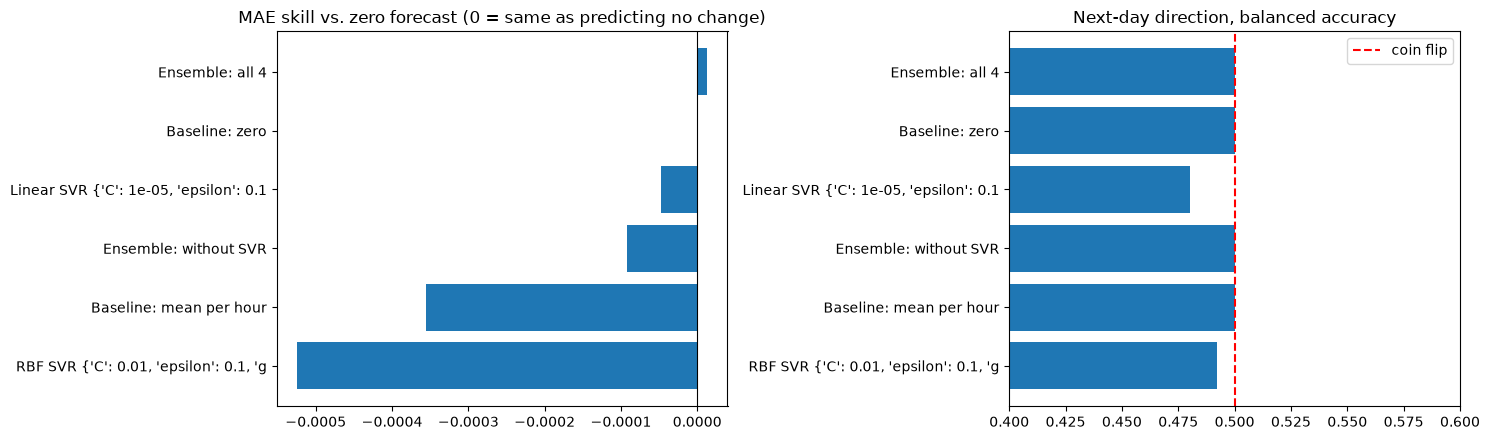

In [8]:
summary = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
cols = ["MAE", "RMSE", "MAE_skill", "R2_oos", "IC", "HourDirAcc", "DayDirAcc_indep", "p_value", "DayBalAcc_indep"]
display(summary[cols].sort_values("MAE").round(4))

s = summary.sort_values("MAE_skill")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(s.index.str.slice(0, 38), s["MAE_skill"]); ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_title("MAE skill vs. zero forecast (0 = same as predicting no change)")
ax[1].barh(s.index.str.slice(0, 38), s["DayBalAcc_indep"]); ax[1].axvline(0.5, color="red", ls="--", label="coin flip")
ax[1].set_xlim(0.4, 0.6); ax[1].set_title("Next-day direction, balanced accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

**Skill per forecast hour.** If there is any signal, it should be in the first hours after the input week.

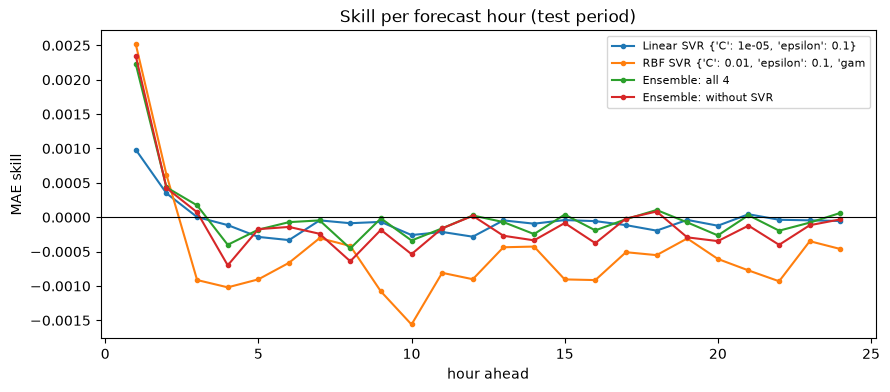

In [9]:
plt.figure(figsize=(10, 4))
mae0_h = np.abs(Yte).mean(axis=0)
for name, pred in test_preds.items():
    if name.startswith("Baseline"):
        continue
    plt.plot(range(1, 25), 1 - np.abs(Yte - pred).mean(axis=0) / mae0_h, marker=".", label=name[:40])
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("hour ahead"); plt.ylabel("MAE skill"); plt.title("Skill per forecast hour (test period)")
plt.legend(fontsize=8); plt.show()

**How different are the members?** An ensemble only helps if its members disagree. The correlation of their test predictions shows how much.

In [10]:
corr = pd.DataFrame({n: p.ravel() for n, p in member_test_preds.items()}).corr()
display(corr.round(2))

,Ridge,Random Forest,Gradient Boosting,SVR
Ridge,1.00,0.67,0.30,0.40
Random Forest,0.67,1.00,0.21,0.17
Gradient Boosting,0.30,0.21,1.00,0.42
SVR,0.40,0.17,0.42,1.00


## 6. Conclusions

Numbers from the run on 5 October 2026 (test period 25 Oct 2023 → 5 Oct 2026). Note: the CV tables round to 4 decimals, so `C = 0.00001` is shown as `0.0000`.

**1. SVR does not find signal in the hourly changes either.**
- **Linear SVR:** the best setting is the strongest regularisation in the grid (`C = 0.00001`). Its predictions are on average only 0.004 % in size, while real hourly moves average 0.33 %, so it is almost the zero forecast. Test MAE skill −0.00005, i.e. equal to "no change". It is the only single model with a positive *validation* skill (+0.0001), but that is far inside the fold-to-fold noise.
- **RBF SVR** shows overfitting very clearly. With `C = 1` and `gamma = "scale"` the train skill reaches **+0.29** while the validation skill drops to **−0.04**. The best setting (`C = 0.01`, `gamma = 0.003`, the smoothest one) still ends at −0.0005 on the test period.
- `epsilon` hardly matters: once `C` is small, the model is nearly flat anyway.

**2. The voting ensemble is the best model of the whole project on MAE, but only just.**
- *Ensemble: all 4* (Ridge, Random Forest, Gradient Boosting, Linear SVR) is the only model with a positive test MAE skill: **+0.000013**. All of Alberto's single models are between −0.0003 and −0.0010.
- That is 0.001 % of the error, so in practice it is **the same as predicting no change**, not a usable forecast.
- Why averaging helps a little: the members disagree. Their test predictions correlate only 0.17–0.67 (Gradient Boosting vs. Random Forest just 0.21), so part of their individual noise cancels out. Adding SVR also improved the ensemble in CV (validation skill −0.0001 with SVR vs. −0.0005 without).

**3. The only trace of signal is in the first hour.** On hour +1 the ensemble has MAE skill +0.0022 and Gradient Boosting +0.0023. For hours 2–24 everything is at zero: whatever is predictable fades after the first hour. `binance-features.ipynb` looks at this hour +1 signal in detail.

**4. Direction: no skill.** The ensemble gets 53.4 % of days right, but balanced accuracy is exactly 0.500: like the other models, it effectively predicts "always slightly up" in a period where 53.5 % of days were up.

**In one sentence:** SVR and the voting ensemble confirm the team's result. Hourly Bitcoin changes are practically unpredictable from the past week, and the best a model can do is stay very close to "no change". Averaging different models is the safest way to get there.
